# **9.  Métodos modernos de Gradient Boosting.**

Temas selectos de aprendizaje de máquina \
Ana Luisa Llamas Martinez

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.dummy import DummyRegressor

## 9.1 Datos: California Housing.

In [2]:
housing = fetch_california_housing(as_frame=True)
housing

{'data':        MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
 0      8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
 1      8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
 2      7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
 3      5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
 4      3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   
 ...       ...       ...       ...        ...         ...       ...       ...   
 20635  1.5603      25.0  5.045455   1.133333       845.0  2.560606     39.48   
 20636  2.5568      18.0  6.114035   1.315789       356.0  3.122807     39.49   
 20637  1.7000      17.0  5.205543   1.120092      1007.0  2.325635     39.43   
 20638  1.8672      18.0  5.329513   1.171920       741.0  2.123209     39.43   
 20639  2.3886      16.0  5.254717   1.162264      1387.0  2.616981     39.37   
 
        Longitude 

In [3]:
X = housing.data
y = housing.target

In [4]:
X.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


In [5]:
y.head()

0    4.526
1    3.585
2    3.521
3    3.413
4    3.422
Name: MedHouseVal, dtype: float64

In [6]:
print(housing.DESCR)

.. _california_housing_dataset:

California Housing dataset
--------------------------

**Data Set Characteristics:**

:Number of Instances: 20640

:Number of Attributes: 8 numeric, predictive attributes and the target

:Attribute Information:
    - MedInc        median income in block group
    - HouseAge      median house age in block group
    - AveRooms      average number of rooms per household
    - AveBedrms     average number of bedrooms per household
    - Population    block group population
    - AveOccup      average number of household members
    - Latitude      block group latitude
    - Longitude     block group longitude

:Missing Attribute Values: None

This dataset was obtained from the StatLib:
https://lib.stat.cmu.edu/datasets/houses.zip

The target variable is the median house value for California districts,
expressed in hundreds of thousands of dollars ($100,000).

This dataset was derived from the 1990 U.S. census, using one row per census
block group. A block g

In [7]:
X.shape

(20640, 8)

In [8]:
X.isna().sum()

MedInc        0
HouseAge      0
AveRooms      0
AveBedrms     0
Population    0
AveOccup      0
Latitude      0
Longitude     0
dtype: int64

In [9]:
X.describe().T

,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000


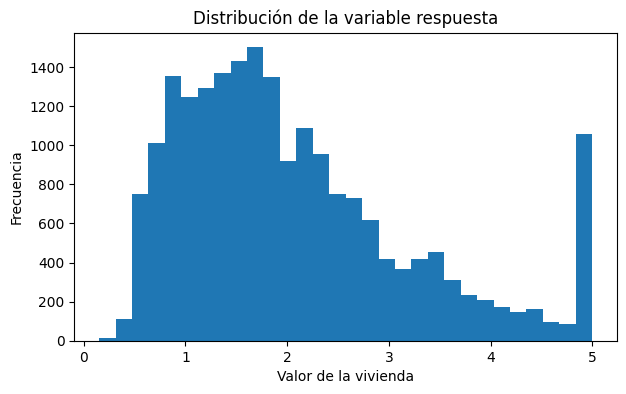

In [10]:
plt.figure(figsize=(7,4))
plt.hist(y, bins=30)
plt.xlabel("Valor de la vivienda")
plt.ylabel("Frecuencia")
plt.title("Distribución de la variable respuesta")
plt.show()

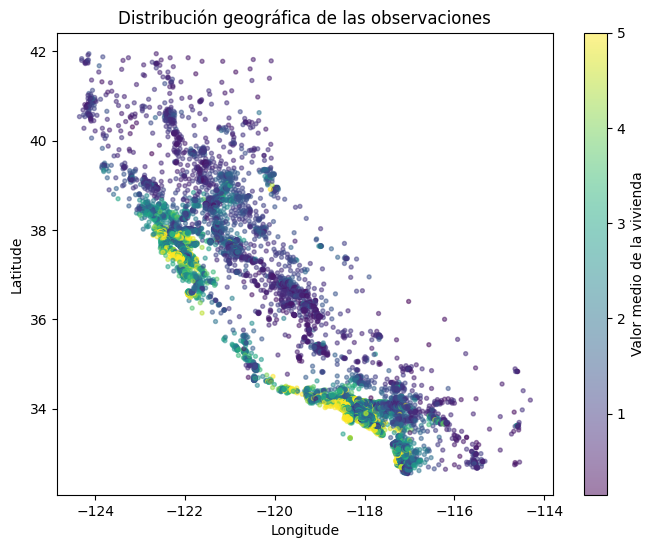

In [11]:
plt.figure(figsize=(8,6))
plt.scatter(X["Longitude"], X["Latitude"], c=y, s=8, alpha = 0.5)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Distribución geográfica de las observaciones")
plt.colorbar(label="Valor medio de la vivienda")

plt.show()

## 9.2 Separación de los datos.

In [12]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

X_train: (16512, 8)
X_test: (4128, 8)


## 9.3 Una referencia inicial: DummyRegressor.

In [13]:
dummy = DummyRegressor(strategy= "mean")
dummy.fit(X_train, y_train)

,"strategy strategy: {""mean"", ""median"", ""quantile"", ""constant""}, default=""mean""Strategy to use to generate predictions.* ""mean"": always predicts the mean of the training set* ""median"": always predicts the median of the training set* ""quantile"": always predicts a specified quantile of the training set, provided with the quantile parameter.* ""constant"": always predicts a constant value that is provided by the user.",'mean'
,"constant constant: int or float or array-like of shape (n_outputs,), default=NoneThe explicit constant as predicted by the ""constant"" strategy. Thisparameter is useful only for the ""constant"" strategy.",None
,"quantile quantile: float in [0.0, 1.0], default=NoneThe quantile to predict using the ""quantile"" strategy. A quantile of0.5 corresponds to the median, while 0.0 to the minimum and 1.0 to themaximum.",None
Name,Type,Value
"constant_ constant_: ndarray of shape (1, n_outputs)Mean or median or quantile of the training targets or constant valuegiven by the user.","ndarray[float64](1, 1)",[[2.07]]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X` hasfeature names that are all strings.","ndarray[object](8,)","['MedInc','HouseAge','AveRooms',...,'AveOccup','Latitude','Longitude']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`.,int,8
n_outputs_ n_outputs_: intNumber of outputs.,int,1


In [14]:
y_pred_dummy = dummy.predict(X_train)

In [15]:
mae_dummy = mean_absolute_error(y_train, y_pred_dummy)
rmse_dummy = np.sqrt(mean_squared_error(y_train, y_pred_dummy))

print(f"MAE:{mae_dummy:.4f}")
print(f"RMSE:{rmse_dummy:.4f}")

MAE:0.9139
RMSE:1.1562


## 9.4 Nuestro primer Gradient Boosting.

In [16]:
gbr = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=2,
    random_state=42
)

In [17]:
gbr.fit(X_train, y_train)

,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",2
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'squared_error', 'absolute_error', 'huber', 'quantile'}, default='squared_error'Loss function to be optimized. 'squared_error' refers to the squarederror for regression. 'absolute_error' refers to the absolute error ofregression and is a robust loss function. 'huber' is acombination of the two. 'quantile' allows quantile regression (use`alpha` to specify the quantile).See:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_quantile.py`for an example that demonstrates quantile regression for creatingprediction intervals with `loss='quantile'`.",'squared_error'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf

In [18]:
y_pred_train = gbr.predict(X_train)

mae_gbr = mean_absolute_error(y_train, y_pred_train)
rmse_gbr = np.sqrt(mean_squared_error(y_train, y_pred_train))

print(f"MAE:{mae_gbr:.4f}")
print(f"RMSE:{rmse_gbr:.4f}")

MAE:0.3984
RMSE:0.5629


## 9.5 ¿Cómo aprende el ensamble?

In [19]:
errores_train = []

for y_pred in gbr.staged_predict(X_train):
    rmse = np.sqrt(mean_squared_error(y_train, y_pred))
    errores_train.append(rmse)

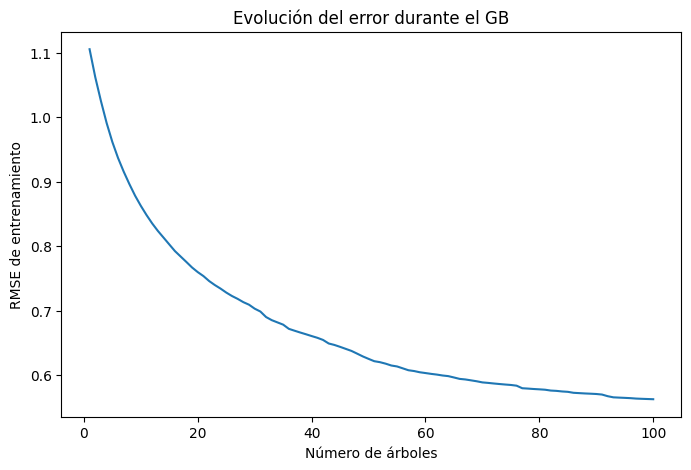

In [20]:
plt.figure(figsize=(8,5))

plt.plot(range(1, len(errores_train) +1), errores_train)

plt.xlabel("Número de árboles")
plt.ylabel("RMSE de entrenamiento")
plt.title("Evolución del error durante el GB")
plt.show()

## 9.6 Learning rate.

In [21]:
learning_rate = [1.0, 0.1, 0.01]

modelos_lr = {}

for lr in learning_rate:
    modelo = GradientBoostingRegressor(
        n_estimators= 100,
        learning_rate=lr,
        max_depth= 2,
        random_state=42
    )

    modelo.fit(X_train, y_train)
    modelos_lr[lr] = modelo

In [22]:
modelos_lr

{1.0: GradientBoostingRegressor(learning_rate=1.0, max_depth=2, random_state=42),
 0.1: GradientBoostingRegressor(max_depth=2, random_state=42),
 0.01: GradientBoostingRegressor(learning_rate=0.01, max_depth=2, random_state=42)}

In [23]:
resultados_lr = []

for lr, modelo in modelos_lr.items():
    pred = modelo.predict(X_train)
    rmse = np.sqrt(mean_squared_error(y_train, pred))
    resultados_lr.append({"learning_rate": lr, "RMSE": rmse})

pd.DataFrame(resultados_lr)

,learning_rate,RMSE
0,1.00,0.468276
1,0.10,0.562853
2,0.01,0.868894


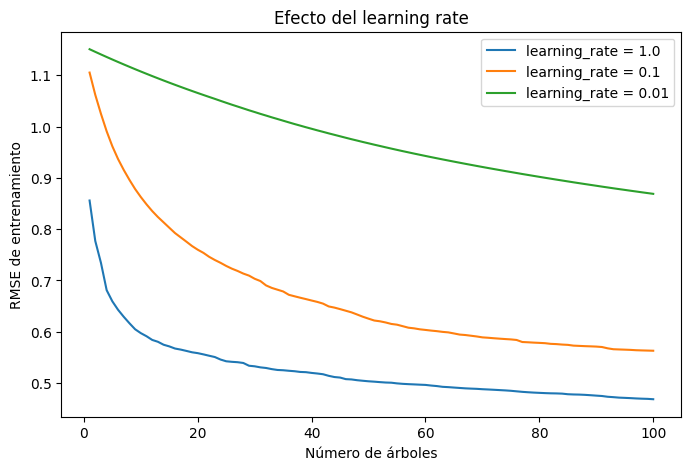

In [24]:
plt.figure(figsize=(8, 5))

for lr, modelo in modelos_lr.items():
    
    errores = []
    
    for pred in modelo.staged_predict(X_train):
        rmse = np.sqrt(
            mean_squared_error(y_train, pred)
        )
        errores.append(rmse)
    
    plt.plot(
        range(1, len(errores) + 1),
        errores,
        label=f"learning_rate = {lr}"
    )

plt.xlabel("Número de árboles")
plt.ylabel("RMSE de entrenamiento")
plt.title("Efecto del learning rate")
plt.legend()
plt.show()

## 9.7 Interacción entre learning rate y número de árboles.

In [25]:
configuraciones = [
    (1.0, 50),
    (0.1, 100),
    (0.05, 200),
    (0.01, 500)
]

resultados = []

for lr, narboles in configuraciones:
    modelo = GradientBoostingRegressor(
            n_estimators= narboles,
            learning_rate=lr,
            max_depth= 2,
            random_state=42
        )
    
    modelo.fit(X_train, y_train)

    pred = modelo.predict(X_train)
    rmse = np.sqrt(mean_squared_error(y_train, pred))

    resultados.append(
        {
            "Tasa de error": lr,
            "Número de árboles": narboles,
            "RMSE": rmse
        }
    )


pd.DataFrame(resultados)
    

,Tasa de error,Número de árboles,RMSE
0,1.00,50,0.503253
1,0.10,100,0.562853
2,0.05,200,0.561326
3,0.01,500,0.630265


## 9.8 Complejidad de los árboles.

In [26]:
profundidades = [1,2,3,4,5]
n_estimadores = 100,
learning_rate = 0.1

In [27]:
depth_error = []
for profundidad in profundidades:
    modelo = GradientBoostingRegressor(
                n_estimators= 100,
                learning_rate=learning_rate,
                max_depth= profundidad,
                random_state=42
            )
    modelo.fit(X_train, y_train)
    
    pred = modelo.predict(X_train)
    rmse = np.sqrt(mean_squared_error(y_train, pred))

    depth_error.append(rmse)

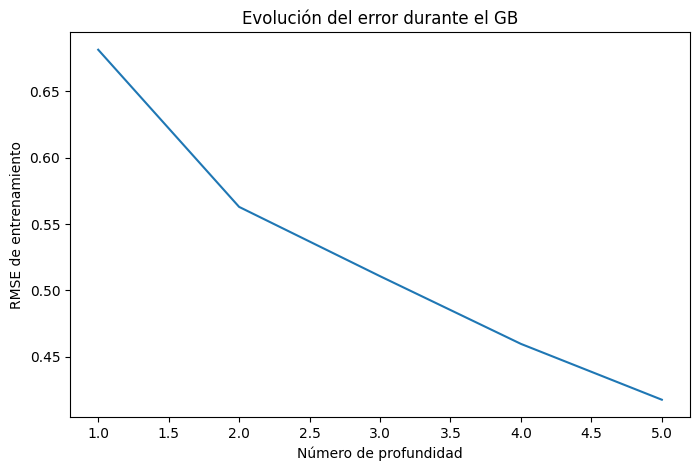

In [28]:
plt.figure(figsize=(8,5))

plt.plot(profundidades, depth_error)

plt.xlabel("Número de profundidad")
plt.ylabel("RMSE de entrenamiento")
plt.title("Evolución del error durante el GB")
plt.show()

## 9.9 Entrenamiento y validación.

In [29]:
X_train_gb, X_val, y_train_gb, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42)

X_train_gb.shape

(13209, 8)

## 9.10 Error de entrenamiento vs. error de validación.

In [30]:
gbr_long = GradientBoostingRegressor(
    n_estimators=500,
    learning_rate=0.1,
    max_depth=2,
    random_state=42
)

gbr_long.fit(X_train_gb, y_train_gb)

,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",500
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",2
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'squared_error', 'absolute_error', 'huber', 'quantile'}, default='squared_error'Loss function to be optimized. 'squared_error' refers to the squarederror for regression. 'absolute_error' refers to the absolute error ofregression and is a robust loss function. 'huber' is acombination of the two. 'quantile' allows quantile regression (use`alpha` to specify the quantile).See:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_quantile.py`for an example that demonstrates quantile regression for creatingprediction intervals with `loss='quantile'`.",'squared_error'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.",0.1
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf

In [31]:
rmse_train = []
rmse_val = []

for pred_train, pred_val in zip(gbr_long.staged_predict(X_train_gb), gbr_long.staged_predict(X_val)):
    rmse_train.append(np.sqrt(mean_squared_error(y_train_gb, pred_train)))
    rmse_val.append(np.sqrt(mean_squared_error(y_val, pred_val)))

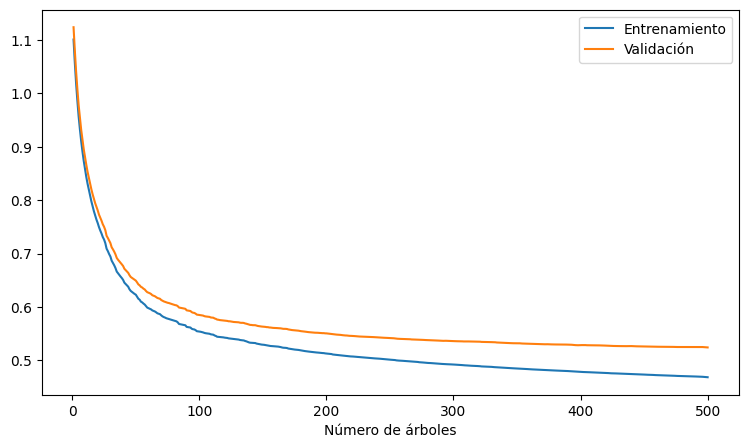

In [32]:
plt.figure(figsize=(9,5))

plt.plot(range(1, len(rmse_train)+1), rmse_train, label = "Entrenamiento")
plt.plot(range(1, len(rmse_val)+1), rmse_val, label = "Validación")
plt.xlabel("Número de árboles")
plt.legend()
plt.show()

## 9.12.1 Early stopping automático en Scikit-Learn.

In [33]:
gbr_auto = GradientBoostingRegressor(
    n_estimators=1000,
    learning_rate=0.1,
    max_depth=2,
    validation_fraction=0.1,
    n_iter_no_change=10,
    tol = 1e-4,
    random_state=42
)

gbr_auto.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",1000
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",2
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"n_iter_no_change n_iter_no_change: int, default=None``n_iter_no_change`` is used to decide if early stopping will be usedto terminate training when validation score is not improving. Bydefault it is set to None to disable early stopping. If set to anumber, it will set aside ``validation_fraction`` size of the trainingdata as validation and terminate training when validation score is notimproving in all of the previous ``n_iter_no_change`` numbers ofiterations.Values must be in the range `[1, inf)`.See:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_early_stopping.py`... versionadded:: 0.20",10
,"loss loss: {'squared_error', 'absolute_error', 'huber', 'quantile'}, default='squared_error'Loss function to be optimized. 'squared_error' refers to the squarederror for regression. 'absolute_error' refers to the absolute error ofregression and is a robust loss function. 'huber' is acombination of the two. 'quantile' allows quantile regression (use`alpha` to specify the quantile).See:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_quantile.py`for an example that demonstrates quantile regression for creatingprediction intervals with `loss='quantile'`.",'squared_error'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.",0.1
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_sample

In [34]:
gbr_auto.n_estimators_

354

## 9.13 Stochastic Gradient Boosting.

In [35]:
gbr_stochastic = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.1,
    max_depth=2,
    subsample=0.8,
    random_state=42
)

gbr_stochastic.fit(X_train_gb, y_train_gb)

,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",200
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",0.8
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",2
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'squared_error', 'absolute_error', 'huber', 'quantile'}, default='squared_error'Loss function to be optimized. 'squared_error' refers to the squarederror for regression. 'absolute_error' refers to the absolute error ofregression and is a robust loss function. 'huber' is acombination of the two. 'quantile' allows quantile regression (use`alpha` to specify the quantile).See:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_quantile.py`for an example that demonstrates quantile regression for creatingprediction intervals with `loss='quantile'`.",'squared_error'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.",0.1
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf

## 9.15 Nuestro primer modelo con XGBoost.

In [36]:
from xgboost import XGBRegressor

In [37]:
xgb = XGBRegressor(n_estimators=200,
                   learning_rate = 0.1,
                   max_depth = 2,
                   objetive = "reg:squarederror",
                   random_state = 42,
                   n_jobs = -1)

In [38]:
xgb.fit(X_train_gb, y_train_gb)

c:\Users\analu\AppData\Local\Programs\Python\Python313\Lib\site-packages\xgboost\training.py:200: UserWarning: [10:04:35] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "objetive" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [39]:
pred_xgb = xgb.predict(X_val)

In [40]:
mae_xgb = mean_absolute_error(y_val, pred_xgb)
rmse_xgb = np.sqrt(mean_squared_error(y_val, pred_xgb))

print(f"MAE: {mae_xgb}")
print(f"RMSE: {rmse_xgb}")

MAE: 0.38219530599551993
RMSE: 0.548988265089522


## 9.16 Comparación inicial.

In [41]:
gbr_compare = GradientBoostingRegressor(n_estimators=200,
                                        learning_rate=0.1,
                                        max_depth=2,
                                        random_state=42)

gbr_compare.fit(X_train_gb, y_train_gb)
pred_gbr = gbr_compare.predict(X_val)

In [42]:
mae_compare = mean_absolute_error(y_val, pred_gbr)
rmse_compare = np.sqrt(mean_squared_error(y_val, pred_gbr))

print(f"MAE: {mae_compare}")
print(f"RMSE: {rmse_compare}")

MAE: 0.3843280005734157
RMSE: 0.5507591403563764


## 9.17 Más hiperparámetros de XGBoost.

In [43]:
xgb_reg = XGBRegressor(
    n_estimators = 300,
    learning_rate = 0.05,
    max_depth = 3,
    subsample = 0.8,
    colsample_bytree = 0.8,
    reg_alpha = 0.1,
    reg_lambda = 1.0,
    objetive = "reg:squarederror",
    random_state = 42,
    n_jobs = -1
)

xgb_reg.fit(X_train_gb, y_train_gb)

c:\Users\analu\AppData\Local\Programs\Python\Python313\Lib\site-packages\xgboost\training.py:200: UserWarning: [10:04:39] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "objetive" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [44]:
pred_xgb_reg = xgb_reg.predict(X_val)
rmse_xgb_reg = np.sqrt(mean_squared_error(y_val, pred_xgb_reg))

In [45]:
rmse_xgb_reg

np.float64(0.5239491618366392)

## Ejercicios

Vamos a experimenta con el modelo GradientBoostingRegressor con los mismos datos.


**9.18.1 Parte 1.** Entrena los cuatro modelos utilizando X_train_gb y y_train_gb.

Completa el siguiente código.

In [46]:
configuraciones1 = [
    ("A", 0.1, 100, 2),
    ("B", 0.05, 200, 2),
    ("C", 0.01, 500, 2),
    ("D", 0.1, 100, 4)
]

Para cada configuración:

- entrena un GradientBoostingRegressor;
- calcula el RMSE de entrenamiento;
- calcula el RMSE de validación;
- guarda los resultados en un DataFrame.

In [47]:
resultados1 = []

for nombre, lr, narboles, maxprof in configuraciones1:
    modelo = GradientBoostingRegressor(
            n_estimators= narboles,
            learning_rate=lr,
            max_depth= maxprof,
            random_state=42
        )
    
    modelo.fit(X_train_gb, y_train_gb)

    pred_t = modelo.predict(X_train_gb)
    pred_v = modelo.predict(X_val)

    rmse_t = np.sqrt(mean_squared_error(y_train_gb, pred_t))
    rmse_v = np.sqrt(mean_squared_error(y_val, pred_v))
    

    resultados1.append(
        {
            "Modelo": nombre,
            "Tasa de error": lr,
            "Número de árboles": narboles,
            "Profundidad máxima": maxprof,
            "RMSE de entrenamiento": rmse_t,
            "RMSE de validación": rmse_v
        }
    )

In [48]:
pd.DataFrame(resultados1)

,Modelo,Tasa de error,Número de árboles,Profundidad máxima,RMSE de entrenamiento,RMSE de validación
0,A,0.10,100,2,0.554203,0.585258
1,B,0.05,200,2,0.559410,0.589458
2,C,0.01,500,2,0.625263,0.652214
3,D,0.10,100,4,0.450161,0.520537


**9.18.2 Parte 2.** Responde brevemente:

1) ¿Cuál configuración obtiene el menor error de entrenamiento?

    **R:** El modelo D 

2) ¿Coincide con la configuración que obtiene el menor error de validación?

    **R:** Sí.

3) Compara A, B y C. ¿Qué observas sobre la relación entre learning_rate y n_estimators?

    **R:** Cuando baja la tasa de error y aumenta el número de árboles, el error de entrenamiento y de validación aumenta.

4) ¿Qué efecto observas al aumentar max_depth de 2 a 4?

    **R:** Bajó considerablemente la tasa de error de entrenamiento.

5) ¿Por qué no deberíamos utilizar X_test para decidir cuál de estas cuatro configuraciones conservar?

    **R:** Porque puede existir fuga de información. 